# Diagonalization iterations

In [1]:
import logging
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt
import jax
from skqd_z2lgt.orchestration.open_output import open_output
from skqd_z2lgt.orchestration.io import load_skqd_result
from skqd_z2lgt.orchestration.common import make_lattice
logging.basicConfig(level=logging.INFO)

In [2]:
string_potential_template = '/data/iiyama/2dz2/string_potential/8x8_{ch0}-{ch1}_pt6.h5'
pkgpath_template = '/data/iiyama/2dz2/production/full156q-kawasaki-{ch0}-{ch1}-{mu:.1f}'

def make_plot(mu, charges):
    with h5py.File(string_potential_template.format(ch0=charges[0], ch1=charges[1])) as source:
        mus = source['mus'][()]
        imu = np.argmin(np.abs(mus - mu))
        pt_energy = source['pt_energies'][imu]
        dmrg_energy = source['dmrg_energies'][imu]
        tsd_energy = source['tsd_energies'][imu]

    parameters = open_output(pkgpath_template.format(ch0=charges[0], ch1=charges[1], mu=mu))
    skqd_energies = load_skqd_result(parameters, 'cr')[0]

    fig, ax = plt.subplots()
    ax.plot(skqd_energies - dmrg_energy, label='SKQD')
    ax.axhline(tsd_energy - dmrg_energy, color='k', linestyle='--', label='TSD')
    # ax.axhline(dmrg - pt, color='b', linestyle=':', label='PT')
    
    ax.set_xlabel('CR iterations', fontsize=14)
    ax.set_ylabel('$E - E_{DMRG}$', fontsize=14)
    ax.grid(axis='y')
    ax.set_ylim(0., (tsd_energy - dmrg_energy) * 1.1)
    ax.legend()

    return fig


INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /data/iiyama/2dz2/production/full156q-kawasaki-20-21-0.6


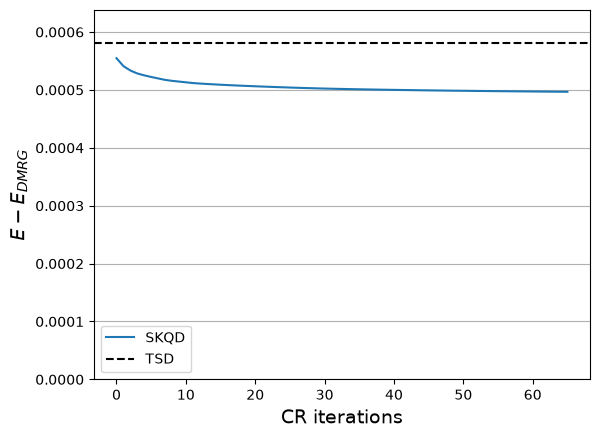

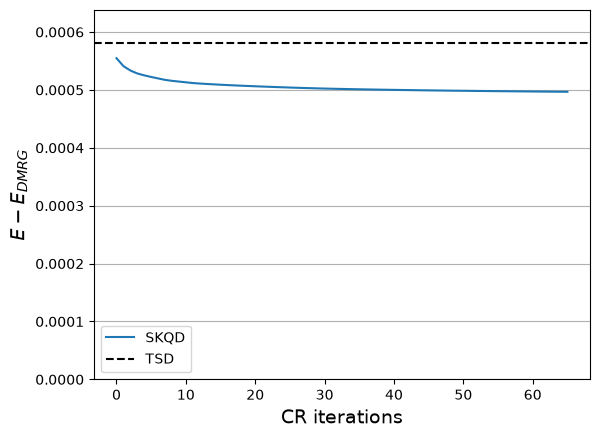

In [ ]:
make_plot(0.6, [20, 21]);

INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /data/iiyama/2dz2/production/full156q-kawasaki-20-22-0.6


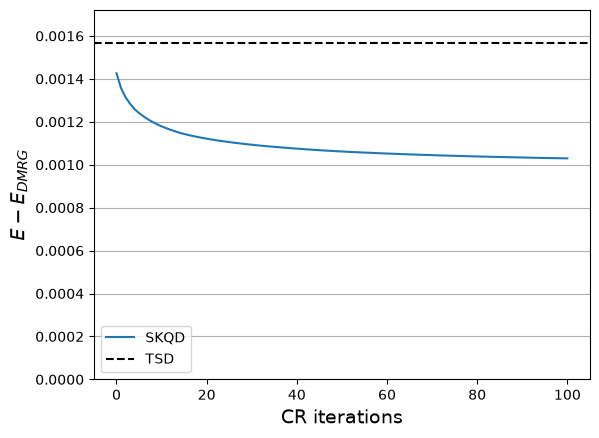

In [4]:
make_plot(0.6, [20, 22]);

INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /data/iiyama/2dz2/production/full156q-kawasaki-20-23-0.6


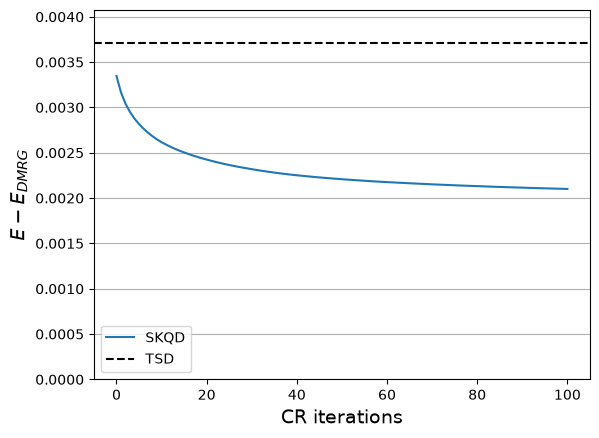

In [5]:
make_plot(0.6, [20, 23]);

INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /data/iiyama/2dz2/production/full156q-kawasaki-20-24-0.6


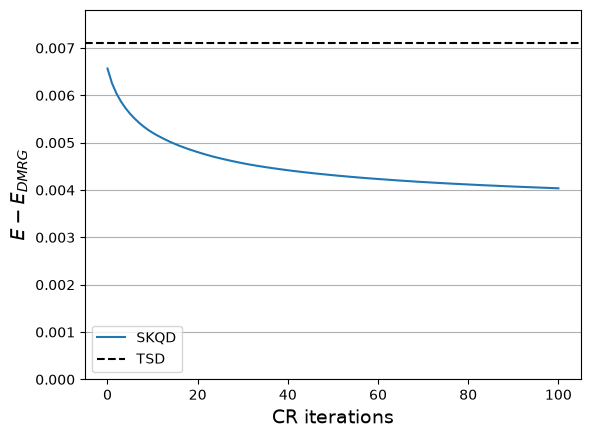

In [6]:
make_plot(0.6, [20, 24]);